# 🛠️ AI IT Helpdesk Agent — Version 1

**LangGraph + Conditional Routing**

This project builds an AI-powered IT Helpdesk Agent using LangGraph.  
The agent classifies user issues, routes them to the right tool, and generates professional responses.

### Architecture

```
              USER
               │
               ▼
        ┌──────────────┐
        │ LLM CLASSIFY │
        └──────┬───────┘
               │
    ┌──────────┼───────────┐
    │          │           │
    ▼          ▼           ▼
 PASSWORD     VPN      GENERAL IT
    │          │           │
    └──────────┼───────────┘
               │
               ▼
        ┌──────────────┐
        │ LLM RESPONSE │
        └──────┬───────┘
               │
               ▼
              END
```

---
## Step 1 — Install Libraries

In [59]:
%pip install -U langgraph langchain-openai python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## Step 2 — Imports

In [60]:
from typing_extensions import TypedDict

from langgraph.graph import (
    StateGraph,
    START,
    END
)

from langchain_openai import ChatOpenAI

from dotenv import load_dotenv

---
## Step 3 — Load Environment Variables

In [61]:
load_dotenv()

True

---
## Step 4 — Create the LLM

The LLM handles:
- **Classification** — deciding what type of issue the user has
- **Response Generation** — turning tool output into a natural answer

In [62]:
import os

model = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-4.1-mini"),
    temperature=0
)

---
## Step 5 — Define the State

State is the data that flows through the graph:

```
User Query → Issue Type → Tool Result → Final Answer
```

In [63]:
class HelpdeskState(TypedDict):

    user_query: str

    issue_type: str

    tool_result: str

    final_response: str

---
## Step 6 — Create Tools

For Version 1, tools are simple Python functions that return troubleshooting instructions.

> **Tool = deterministic function that does a specific job.**

### 6a — Password Tool

In [64]:
def password_help():
    return """
Password Reset Instructions:

1. Open the company login portal.
2. Click 'Forgot Password'.
3. Verify your registered email.
4. Create a new password.
5. Login again.

If the reset fails, contact IT support.
"""

### 6b — VPN Tool

In [65]:
def vpn_help():
    return """
VPN Troubleshooting:

1. Check internet connection.
2. Restart the VPN application.
3. Verify username and password.
4. Disconnect and reconnect.
5. Restart the computer.

If the issue continues,
a support ticket may be required.
"""

### 6c — General IT Tool

In [66]:
def general_it_help():
    return """
General IT Troubleshooting:

1. Restart the application.
2. Restart the computer.
3. Check network connectivity.
4. Check for software updates.
5. Contact IT support if the issue persists.
"""

---
## Step 7 — Node 1: LLM Classifier

The first AI node. It reads the user's query and classifies it into one of three categories:
- `password`
- `vpn`
- `general`

In [67]:
def classify_issue(
    state: HelpdeskState
):

    query = state["user_query"]

    prompt = f"""
Classify this IT support request.

Request:
{query}

Choose exactly one category:

password
vpn
general

Return only the category name.
"""

    response = model.invoke(prompt)

    issue_type = response.content.strip().lower()

    return {
        "issue_type": issue_type
    }

---
## Step 8 — Routing Function

This is our **Conditional Router**. It decides which tool node runs next based on the classification.

In [68]:
def route_issue(
    state: HelpdeskState
):

    issue_type = state["issue_type"]

    if issue_type == "password":
        return "password"

    elif issue_type == "vpn":
        return "vpn"

    else:
        return "general"

---
## Step 9 — Tool Nodes

Each tool node calls its corresponding function and writes the result into state.

### 9a — Password Node

In [69]:
def password_node(
    state: HelpdeskState
):

    result = password_help()

    return {
        "tool_result": result
    }

### 9b — VPN Node

In [70]:
def vpn_node(
    state: HelpdeskState
):

    result = vpn_help()

    return {
        "tool_result": result
    }

### 9c — General IT Node

In [71]:
def general_node(
    state: HelpdeskState
):

    result = general_it_help()

    return {
        "tool_result": result
    }

---
## Step 10 — Final LLM Response Node

The LLM converts the tool output into a natural, professional response.

In [72]:
def generate_response(
    state: HelpdeskState
):

    prompt = f"""
You are an IT Helpdesk Assistant.

User Issue:
{state['user_query']}

Troubleshooting Information:
{state['tool_result']}

Give a short, clear,
professional answer to the user.

Do not invent additional technical details.
"""

    response = model.invoke(prompt)

    return {
        "final_response":
        response.content
    }

---
## Step 11 — Build the Graph

Now we assemble all nodes and edges into a LangGraph `StateGraph`.

In [73]:
# Create the graph builder
builder = StateGraph(
    HelpdeskState
)

### 11a — Add Nodes

In [74]:
builder.add_node(
    "classify_issue",
    classify_issue
)

builder.add_node(
    "password_help",
    password_node
)

builder.add_node(
    "vpn_help",
    vpn_node
)

builder.add_node(
    "general_help",
    general_node
)

builder.add_node(
    "generate_response",
    generate_response
)

### 11b — Add Edges

Connect `START → classify_issue`

In [75]:
builder.add_edge(
    START,
    "classify_issue"
)

### 11c — Add Conditional Routing

This is the key part — the graph branches based on the LLM's classification:

```
classify_issue
      │
  route_issue
  ┌───┼────┐
  ▼   ▼    ▼
 PWD  VPN  GEN
```

In [76]:
builder.add_conditional_edges(
    "classify_issue",
    route_issue,
    {
        "password":
            "password_help",

        "vpn":
            "vpn_help",

        "general":
            "general_help"
    }
)

### 11d — Connect Tool Nodes → Final Response → END

In [77]:
builder.add_edge(
    "password_help",
    "generate_response"
)

builder.add_edge(
    "vpn_help",
    "generate_response"
)

builder.add_edge(
    "general_help",
    "generate_response"
)

builder.add_edge(
    "generate_response",
    END
)

---
## Step 12 — Compile the Graph

In [78]:
helpdesk_graph = builder.compile()

---
## Step 13 — Visualize the Graph

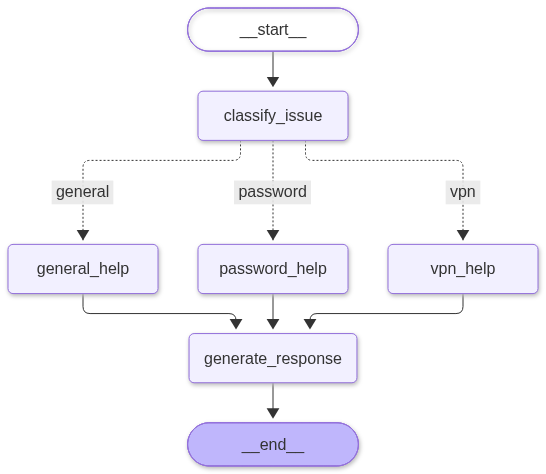

In [79]:
from IPython.display import (
    Image,
    display
)

display(
    Image(
        helpdesk_graph
        .get_graph()
        .draw_mermaid_png()
    )
)

---
## Step 14 — Test: VPN Issue

In [80]:
result = helpdesk_graph.invoke(
    {
        "user_query":
        "My VPN is not connecting",

        "issue_type":
        "",

        "tool_result":
        "",

        "final_response":
        ""
    }
)

print(result["final_response"])

Thanks for letting us know. Please try the following steps in order:

1. Make sure your internet connection is working.  
2. Close and restart the VPN application.  
3. Verify that you’re entering the correct username and password.  
4. Disconnect (if partially connected) and try reconnecting to the VPN.  
5. Restart your computer and attempt to connect again.

If the VPN still won’t connect after these steps, let me know and I’ll create a support ticket for further investigation.


### Inspect the entire state

Students can see exactly what travelled through the graph.

In [81]:
print(result)

{'user_query': 'My VPN is not connecting', 'issue_type': 'vpn', 'tool_result': '\nVPN Troubleshooting:\n\n1. Check internet connection.\n2. Restart the VPN application.\n3. Verify username and password.\n4. Disconnect and reconnect.\n5. Restart the computer.\n\nIf the issue continues,\na support ticket may be required.\n', 'final_response': 'Thanks for letting us know. Please try the following steps in order:\n\n1. Make sure your internet connection is working.  \n2. Close and restart the VPN application.  \n3. Verify that you’re entering the correct username and password.  \n4. Disconnect (if partially connected) and try reconnecting to the VPN.  \n5. Restart your computer and attempt to connect again.\n\nIf the VPN still won’t connect after these steps, let me know and I’ll create a support ticket for further investigation.'}


---
## Step 15 — Test: Password Issue

In [82]:
result2 = helpdesk_graph.invoke(
    {
        "user_query":
        "I forgot my password",

        "issue_type":
        "",

        "tool_result":
        "",

        "final_response":
        ""
    }
)

print(result2["final_response"])

You can reset your password by following these steps:

1. Open the company login portal.  
2. Click on **“Forgot Password”**.  
3. Verify your registered email address when prompted.  
4. Create a new password.  
5. Log in again using your new password.

If the reset does not work at any point, please contact IT support for further assistance.


---
## Step 16 — Test: General IT Issue

In [83]:
result3 = helpdesk_graph.invoke(
    {
        "user_query":
        "My laptop is very slow",

        "issue_type":
        "",

        "tool_result":
        "",

        "final_response":
        ""
    }
)

print(result3["final_response"])

Thanks for reaching out. Please try the following steps:

1. Save your work and restart your laptop.
2. After restart, check if it’s still slow when running your usual applications.
3. Make sure your network connection is stable.
4. Check for and install any available software or system updates.

If the laptop is still very slow after these steps, please contact IT support so we can investigate further.


---
## Step 17 — Compare All Three Routes

Verify each query was classified correctly.

In [84]:
print("=" * 50)
print("VPN Test")
print(f"  Query:      {result['user_query']}")
print(f"  Classified: {result['issue_type']}")
print()

print("=" * 50)
print("Password Test")
print(f"  Query:      {result2['user_query']}")
print(f"  Classified: {result2['issue_type']}")
print()

print("=" * 50)
print("General IT Test")
print(f"  Query:      {result3['user_query']}")
print(f"  Classified: {result3['issue_type']}")
print()

VPN Test
  Query:      My VPN is not connecting
  Classified: vpn

Password Test
  Query:      I forgot my password
  Classified: password

General IT Test
  Query:      My laptop is very slow
  Classified: general



---
## ✅ What We Built

```
User Query
    ↓
LLM Classification  (classify_issue)
    ↓
Conditional Routing  (route_issue)
    ↓
Tool Execution       (password / vpn / general)
    ↓
LLM Response         (generate_response)
    ↓
Final Answer
```

### Concepts Covered

| Concept | Where |
|---------|-------|
| State | `HelpdeskState` TypedDict |
| Nodes | `classify_issue`, tool nodes, `generate_response` |
| Edges | `START → classify → ... → response → END` |
| Conditional Routing | `route_issue` + `add_conditional_edges` |
| LLM Node | Classifier + Response Generator |
| Tools | `password_help`, `vpn_help`, `general_it_help` |
| Agent-style Workflow | LLM decides → route → tool → LLM responds |

---

### 🚀 Next Steps (Version 2)

- Convert tools to LangChain `@tool` decorated functions
- Let the LLM decide which tool to call (instead of manual routing)
- Add a tool-calling agent loop
- Add human-in-the-loop ticket creation